<a href="https://colab.research.google.com/github/AkashDAVLabs/DAV-lab-programs/blob/main/logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
from google.colab import files

# Download the diabetes dataset directly
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

# Save it as a CSV file
df.to_csv("diabetes.csv", index=False)

print("Diabetes dataset created successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

# Optional: Download the CSV file to your computer
files.download("diabetes.csv")


Diabetes dataset created successfully!
Dataset shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# Logistic Regression for Binary Classification
# Diabetes Dataset

# Step 1: Import the required libraries

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import accuracy_score

# Step 2: Display the diabetes dataset

print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# Step 3: Separate input and output

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Step 4: Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Step 5: Build and train the Logistic Regression model

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

# Step 6: Predict the test results

y_pred = model.predict(X_test)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)

# Step 7: Calculate accuracy

print("\nAccuracy:", accuracy_score(y_test, y_pred))

# Step 8: Display the confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Step 9: Calculate evaluation metrics

print("\nPrecision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1-Score:", f1_score(
    y_test, y_pred, zero_division=0
))


Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

Actual Values:
[1 1 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0
 1 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 0 1 1 0 1 1 1 0 0 1 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 1
 1 1 1 0 0 0 0 0 1 0 1 1 0 1

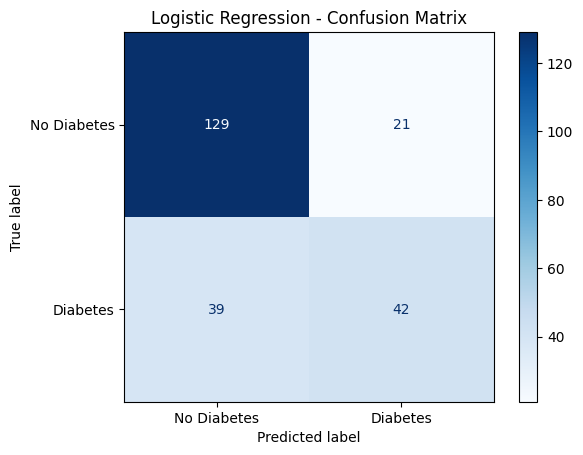

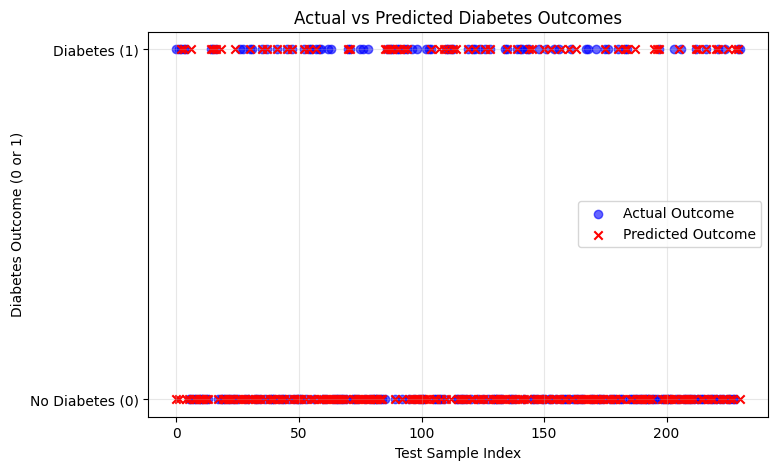

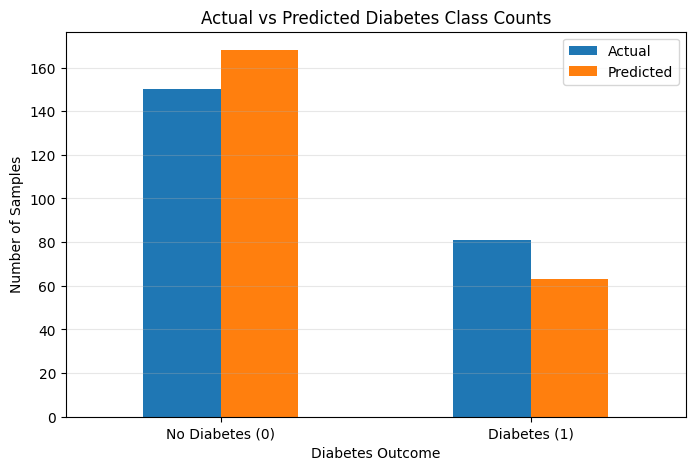

In [4]:

# Step 10: Plot Confusion Matrix Heatmap

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()


# Step 11: Plot Actual vs Predicted Outcomes

plt.figure(figsize=(8, 5))

plt.scatter(
    range(len(y_test)),
    y_test.values,
    color="blue",
    alpha=0.6,
    label="Actual Outcome"
)

plt.scatter(
    range(len(y_pred)),
    y_pred,
    color="red",
    marker="x",
    label="Predicted Outcome"
)

plt.xlabel("Test Sample Index")
plt.ylabel("Diabetes Outcome (0 or 1)")
plt.title("Actual vs Predicted Diabetes Outcomes")
plt.yticks([0, 1], ["No Diabetes (0)", "Diabetes (1)"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Step 12: Plot Actual vs Predicted Class Counts

import pandas as pd

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

counts = pd.DataFrame({
    "Actual": comparison["Actual"].value_counts().reindex([0, 1], fill_value=0),
    "Predicted": comparison["Predicted"].value_counts().reindex([0, 1], fill_value=0)
})

counts.index = ["No Diabetes (0)", "Diabetes (1)"]

counts.plot(kind="bar", figsize=(8, 5))

plt.title("Actual vs Predicted Diabetes Class Counts")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()
